# PDAC Incomplete_Cases — pan-cancer Hist2Pheno

195 PDAC cores without a cell-type CSV. Notebook draws the **5 largest**. No TLS / SRI / TNI.

Checkpoint: `data/PanCancer/result_all_spatial/cross_dataset_cv/D_emph_L2_spatial_pancancer/best_mlp_gpu.pt`

```bash
CUDA_DEVICE=0 bash code/External_val/PDAC_unlabel/demo.sh predict
```


In [4]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val"))

import unlabeled_external as ue

COHORT = "PDAC_unlabel"
SAVE_FIGURES = False
FIGSIZE = (17.2, 12.5)
DPI = 160
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 3.0

cov = ue.coverage(COHORT)
samples = ue.viz_samples(COHORT)
print(f"{COHORT}: {len(cov)} unlabeled slides; drawing {len(samples)}")
print("viz", samples)
display(cov.loc[cov["sample"].isin(samples)])


PDAC_unlabel: 195 unlabeled slides; drawing 5
viz ['Charvill-94_c005_v001_r001_reg075', 'Charvill-94_c005_v001_r001_reg093', 'Charvill-94_c005_v001_r001_reg072', 'Charvill-94_c005_v001_r001_reg047', 'Charvill-94_c005_v001_r001_reg037']


,sample,n_feat_mb,feat,pred,he
0,Charvill-94_c005_v001_r001_reg075,73.91,True,True,True
1,Charvill-94_c005_v001_r001_reg093,70.45,True,True,True
2,Charvill-94_c005_v001_r001_reg072,67.86,True,True,True
3,Charvill-94_c005_v001_r001_reg047,66.54,True,True,True
4,Charvill-94_c005_v001_r001_reg037,66.43,True,True,True


## Predicted L1 / L12 / L2 (row 1 HE, row 2 points)

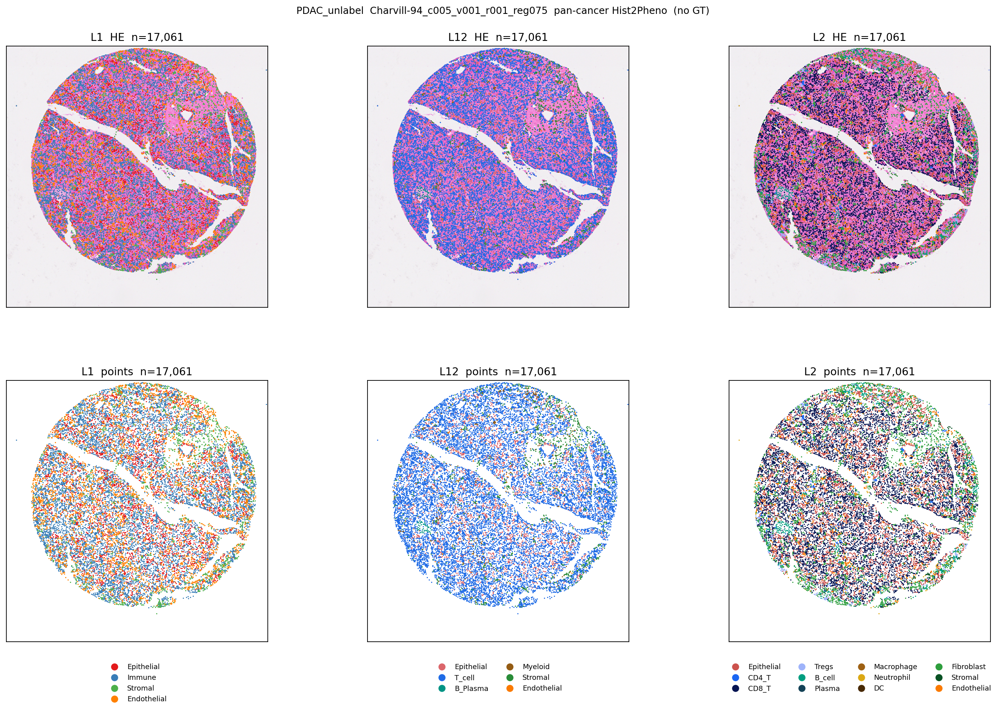

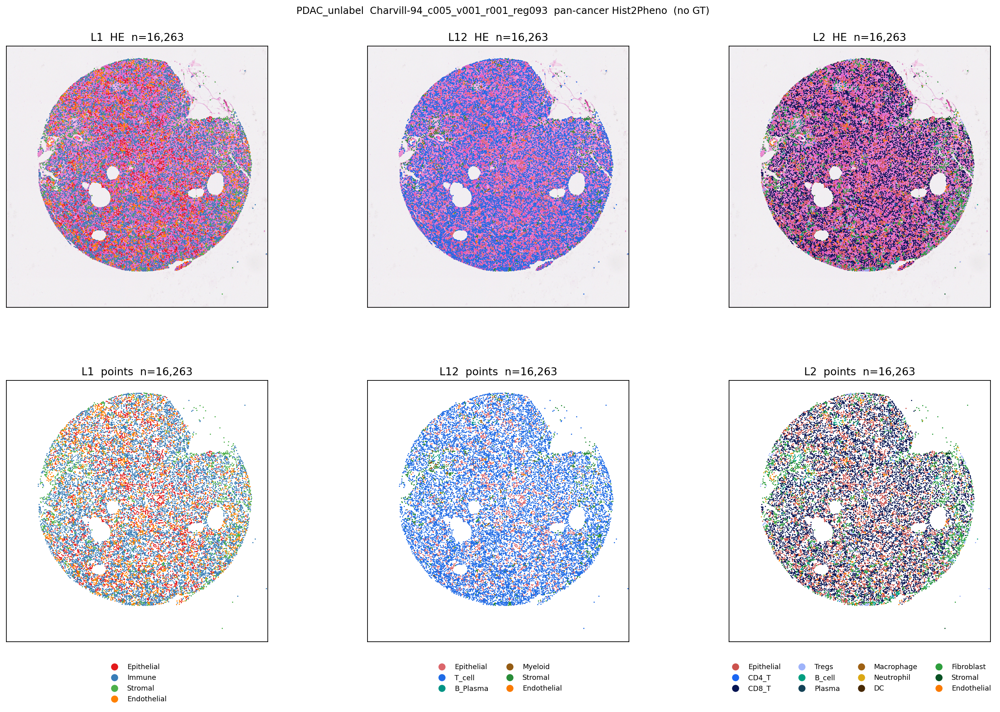

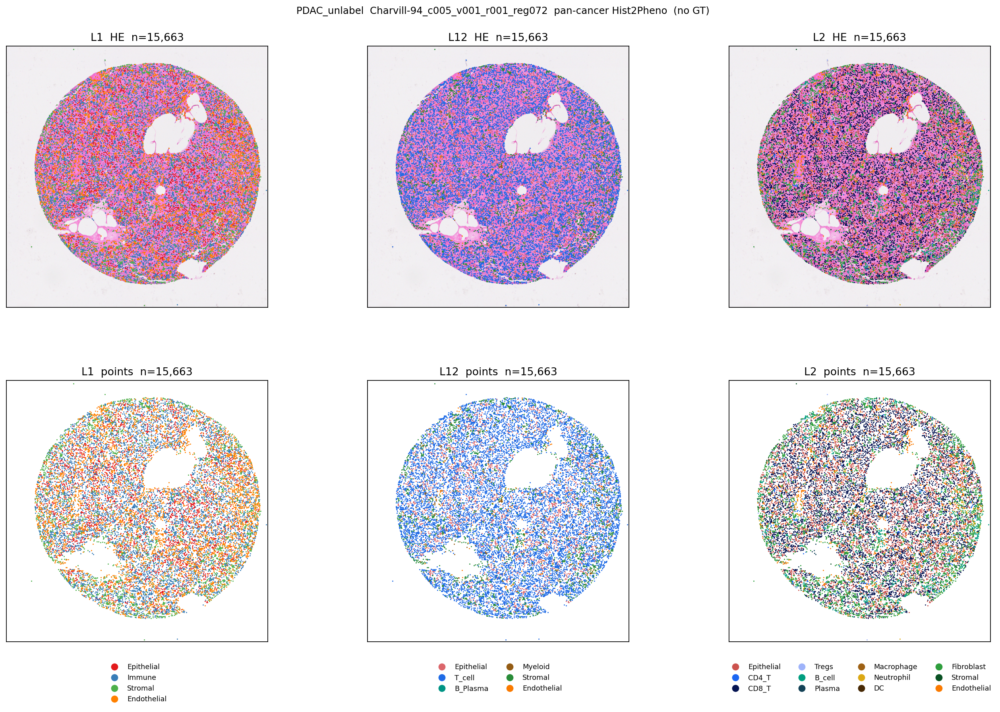

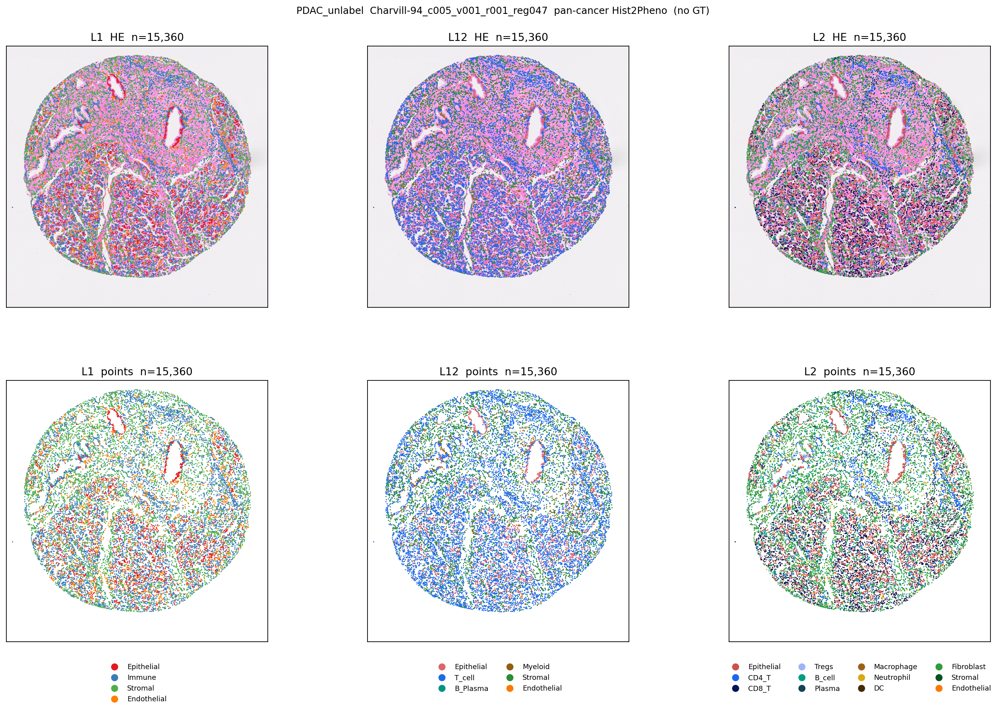

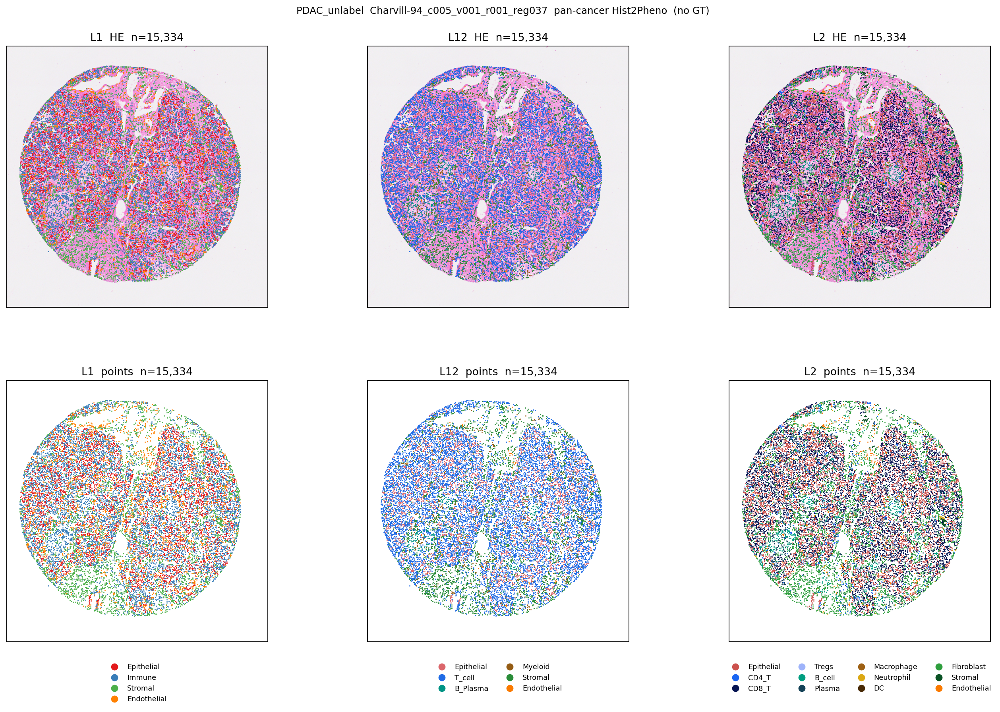

In [5]:
display(Markdown("## Predicted L1 / L12 / L2 (row 1 HE, row 2 points)"))
for sample in samples:
    pred = ue.pred_h5ad(ue._cohort(COHORT), sample)
    if not pred.is_file():
        print("missing pred", sample, "— run demo.sh predict")
        continue
    figs = ue.plot_spatial(
        COHORT,
        [sample],
        save=SAVE_FIGURES,
        figsize=FIGSIZE,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        he_max_side=HE_MAX_SIDE,
        marker_px=MARKER_PX,
    )
    for fig in figs:
        display(fig)
        plt.close(fig)


## Predicted composition (no GT)

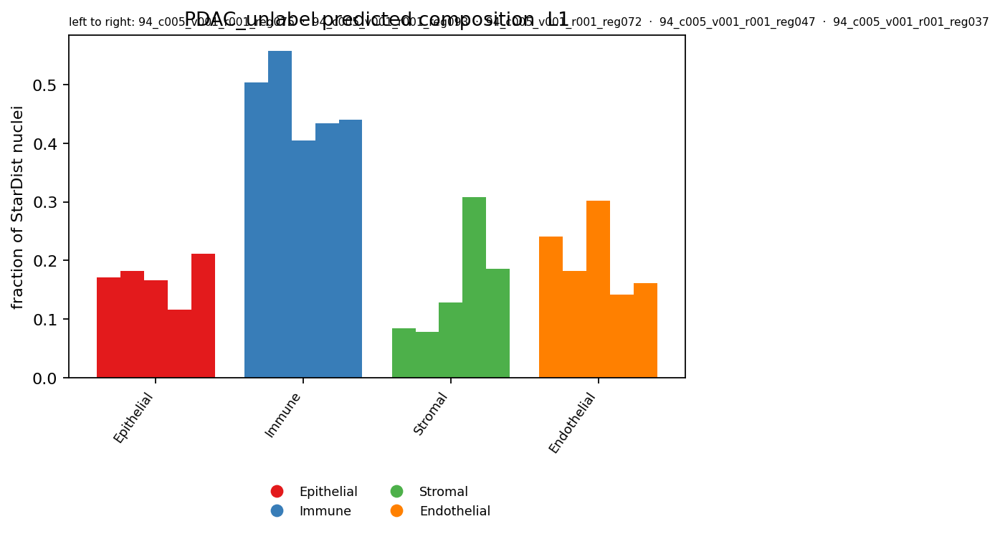

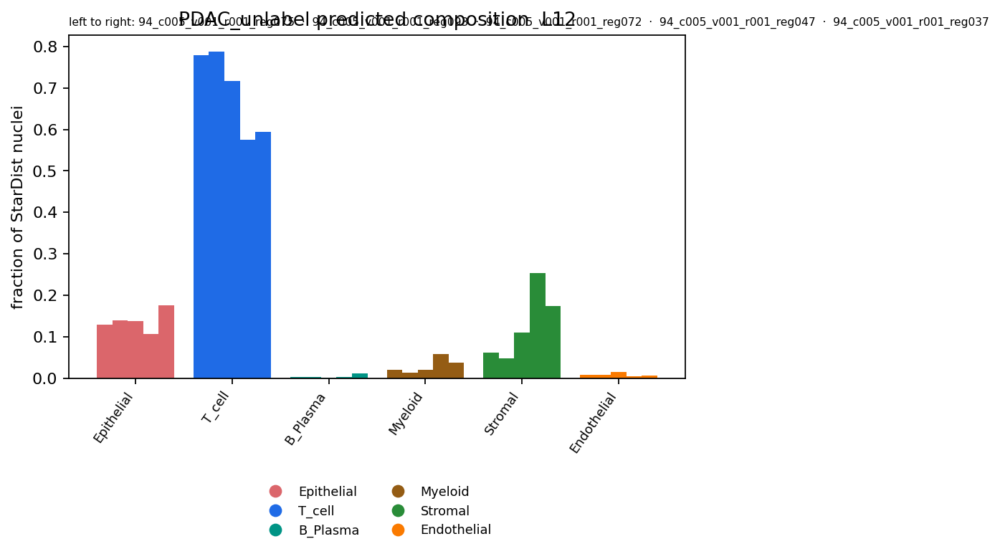

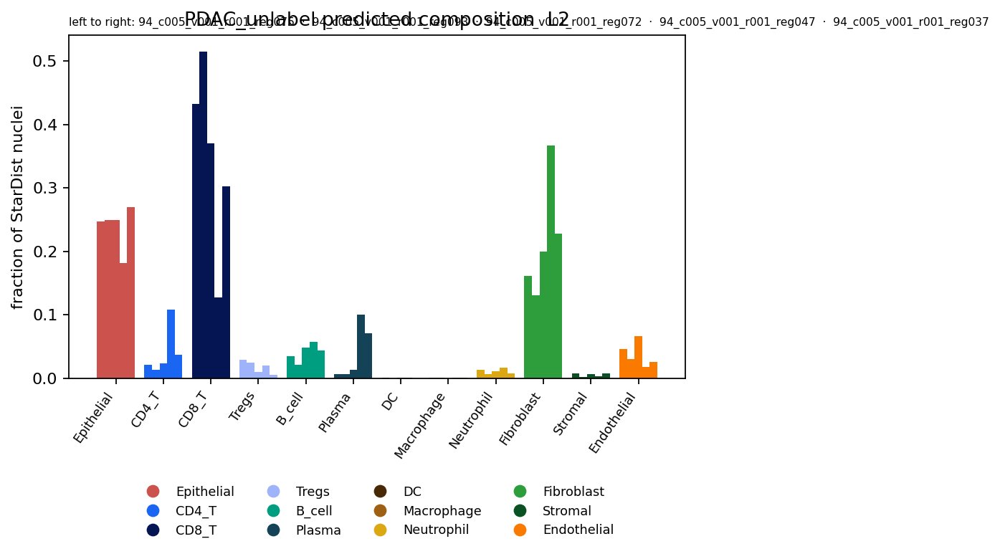

In [3]:
display(Markdown("## Predicted composition (no GT)"))
have = [s for s in samples if ue.pred_h5ad(ue._cohort(COHORT), s).is_file()]
if have:
    figs = ue.plot_composition(COHORT, have, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI)
    for fig in figs:
        display(fig)
        plt.close(fig)
